# Online Retail: Predicting Customer Purchase Counts over the Next 90 Days

**Research question:** Can a customer's purchasing behaviour in the 90 days before 1 September 2011 predict the number of distinct purchase invoices they will place in the following 90 days?

- **Unit of analysis:** one customer (`CustomerID`).
- **Prediction point:** 1 September 2011.
- **Observation window:** 1 Dec 2010 through 31 August 2011 (9 months).
- **Outcome window:** 1 September 2011 through 1 Dec 2011 (3 months).
- **Target:** `purchase_count_90d`, the number of **distinct completed invoices** for that customer during the outcome window.
- **Eligible population:** customers with at least one completed purchase during the observation window.

An invoice often appears on multiple rows because each row represents an invoice line (a product on an invoice). Therefore, counting rows would count product lines, not purchases. This project uses the number of distinct invoice numbers as an operational definition of purchase/order count.

The data comes from the [UCI Machine Learning Repository: Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), containing 541,909 invoice-line records from 1 December 2010 to 9 December 2011. Dataset DOI: [10.24432/C5BW33](https://doi.org/10.24432/C5BW33).

**Important scope limitation:** because customers are selected based on having purchased in the observation window, this model predicts future purchase counts for recently active customers. It does not predict reactivation among inactive customers. A random customer-level test split evaluates generalization to held-out customers in this retailer and historical period; it does not prove performance in a different future calendar period.

Run the notebook from top to bottom. Do not use the final test results to choose features or tune models.

## 1. Setup and reproducibility

The notebook uses a fixed date cutoff and fixed random seed. The raw workbook is downloaded from UCI and stored in `data/`. Keep the data file out of a public repository unless the course specifically asks you to include it.

In [38]:
# If needed, uncomment and run this once:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RANDOM_STATE = 42
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)


Note: you may need to restart the kernel to use updated packages.
pandas: 3.1.1
NumPy: 2.5.5



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Download and load the data

The UCI download is a ZIP file containing `Online Retail.xlsx`. If you already have the workbook, put it at `data/Online Retail.xlsx` and skip the download.

In [40]:
xlsx_path = DATA_DIR / "Online Retail.xlsx"
zip_path = DATA_DIR / "online_retail.zip"
uci_zip_url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

if not xlsx_path.exists():
    if not zip_path.exists():
        print("Downloading the UCI dataset...")
        urlretrieve(uci_zip_url, zip_path)

    with ZipFile(zip_path) as zf:
        excel_members = [name for name in zf.namelist() if name.lower().endswith(".xlsx")]
        if not excel_members:
            raise FileNotFoundError("The downloaded UCI ZIP did not contain an .xlsx file.")
        extracted_path = Path(zf.extract(excel_members[0], DATA_DIR))
        if extracted_path != xlsx_path:
            extracted_path.replace(xlsx_path)

raw = pd.read_excel(xlsx_path, engine="openpyxl")
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())


Raw shape: 541,909 rows × 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Understand the raw data

Each row is an **invoice line**, not a whole purchase or a customer. Relevant columns include:

- `InvoiceNo`: invoice identifier; values beginning with `C` indicate cancellations.
- `StockCode` and `Description`: product identifiers/descriptions.
- `Quantity` and `UnitPrice`: quantity and unit price for this invoice line.
- `InvoiceDate`: date/time of the invoice.
- `CustomerID`: customer identifier; some rows have no customer ID.
- `Country`: customer's country.

The checks below identify missing identifiers, cancellations, returns/adjustments, invalid prices, and exact duplicate rows. These categories may overlap.

In [41]:
print("Data types and non-null counts:")
raw.info()

quality_counts = pd.Series({
    "raw_rows": len(raw),
    "missing_customer_id": raw["CustomerID"].isna().sum(),
    "missing_invoice_date": raw["InvoiceDate"].isna().sum(),
    "cancellation_invoice_lines": raw["InvoiceNo"].astype(str).str.upper().str.startswith("C").sum(),
    "quantity_zero_or_negative": (raw["Quantity"] <= 0).sum(),
    "unit_price_zero_or_negative": (raw["UnitPrice"] <= 0).sum(),
    "exact_duplicate_rows": raw.duplicated().sum(),
})

display(quality_counts.to_frame("count"))
display(raw.describe(include="all").T)


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


,count
raw_rows,541909
missing_customer_id,135080
missing_invoice_date,0
cancellation_invoice_lines,9288
quantity_zero_or_negative,10624
unit_price_zero_or_negative,2517
exact_duplicate_rows,5268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Clean transaction records

For this analysis, a **completed purchase line** must have a known customer, a valid invoice date, a non-cancellation invoice, positive quantity, and positive unit price. Exact duplicate rows are removed. This excludes cancellation invoices and negative-quantity return/adjustment lines from both predictors and target counts.

These decisions define what counts as a purchase. Report the number of records removed and acknowledge that excluding returns means the target measures completed purchase invoices, not net purchasing after returns.

In [42]:
df = raw.copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")

not_cancellation = ~df["InvoiceNo"].str.upper().str.startswith("C", na=False)
valid_rows = (
    df["CustomerID"].notna()
    & df["InvoiceDate"].notna()
    & df["StockCode"].notna()
    & not_cancellation
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)

n_before = len(df)
clean = df.loc[valid_rows].drop_duplicates().copy()
clean["CustomerID"] = clean["CustomerID"].astype("int64").astype(str)
clean["InvoiceNo"] = clean["InvoiceNo"].astype(str)
clean["LineSales"] = clean["Quantity"] * clean["UnitPrice"]
clean["PurchaseDate"] = clean["InvoiceDate"].dt.normalize()

print(f"Rows before cleaning: {n_before:,}")
print(f"Rows after cleaning:  {len(clean):,}")
print(f"Rows removed:         {n_before - len(clean):,}")
print(f"Date range retained:  {clean['InvoiceDate'].min()} to {clean['InvoiceDate'].max()}")
print(f"Customers retained:   {clean['CustomerID'].nunique():,}")

assert (clean["Quantity"] > 0).all()
assert (clean["UnitPrice"] > 0).all()
assert not clean["InvoiceNo"].str.upper().str.startswith("C").any()


Rows before cleaning: 541,909
Rows after cleaning:  392,692
Rows removed:         149,217
Date range retained:  2010-12-01 08:26:00 to 2011-12-09 12:50:00
Customers retained:   4,338


## 5. Focused exploratory data analysis

Look at transaction volume over time and the distribution of customer invoice counts. The count distribution is often right-skewed: many customers make relatively few purchases, while a small number purchase frequently. This matters when choosing metrics and interpreting errors.

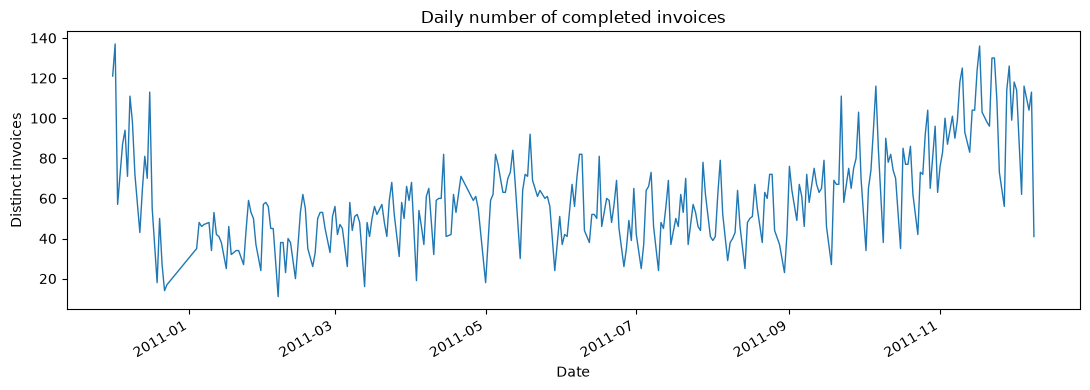

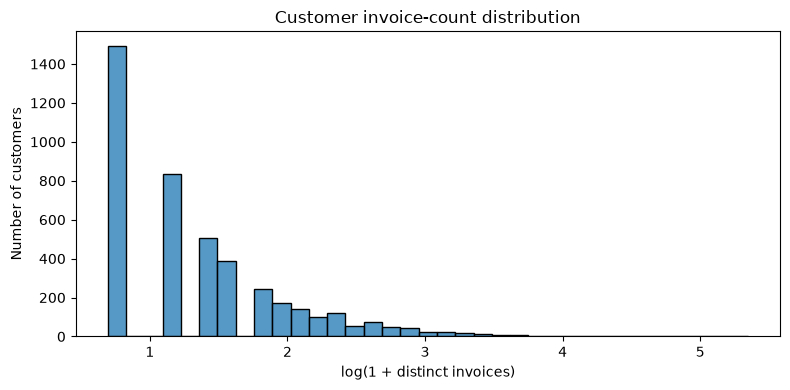

Median invoices per customer over the full dataset: 2.0
90th percentile: 9.0


In [43]:
daily_invoice_count = clean.groupby("PurchaseDate")["InvoiceNo"].nunique()

fig, ax = plt.subplots(figsize=(11, 4))
daily_invoice_count.plot(ax=ax, linewidth=1)
ax.set(title="Daily number of completed invoices", xlabel="Date", ylabel="Distinct invoices")
plt.tight_layout()
plt.show()

all_customer_counts = clean.groupby("CustomerID")["InvoiceNo"].nunique()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(np.log1p(all_customer_counts), bins=35, ax=ax)
ax.set(title="Customer invoice-count distribution", xlabel="log(1 + distinct invoices)", ylabel="Number of customers")
plt.tight_layout()
plt.show()

print("Median invoices per customer over the full dataset:", all_customer_counts.median())
print("90th percentile:", all_customer_counts.quantile(0.90))


## 6. Define the prediction task and construct one row per customer

The date windows are fixed before training:

- **Observation window:** 1 Dec 2010 to 31 August 2011.
- **Prediction cutoff:** 1 September 2011.
- **Outcome window:** 1 September 2011 to 1 Dec 2011.

Only customers with at least one completed invoice in the observation window are included. The target is the number of **distinct invoice numbers** in the outcome window. A customer with no purchase in the outcome window receives target value zero.

Predictors are computed only from the observation window. The future outcome is joined after feature creation and is never used as an input.

In [44]:
CUTOFF = pd.Timestamp("2011-09-01")

OBS_START = pd.Timestamp("2010-12-01")
TARGET_END = pd.Timestamp("2011-12-02")  # exclusive

OBS_MONTHS = 9

# Separate observation and outcome windows.
observation = clean.loc[
    (clean["InvoiceDate"] >= OBS_START)
    & (clean["InvoiceDate"] < CUTOFF)
].copy()

outcome = clean.loc[
    (clean["InvoiceDate"] >= CUTOFF)
    & (clean["InvoiceDate"] < TARGET_END)
].copy()

# Features from the observation window only.
features = observation.groupby("CustomerID").agg(
    items_purchased=("Quantity", "sum"),
    total_spend=("LineSales", "sum"),
    unique_products=("StockCode", "nunique"),
    active_days=("PurchaseDate", "nunique"),
    last_purchase=("InvoiceDate", "max"),
)

# Aggregate invoice lines first. One invoice can contain many product rows.
invoice_summary = (
    observation.groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        invoice_spend=("LineSales", "sum"),
        invoice_quantity=("Quantity", "sum")
    )
)

order_features = invoice_summary.groupby("CustomerID").agg(
    order_count=("InvoiceNo", "nunique"),
    avg_order_value=("invoice_spend", "mean"),
    avg_items_per_order=("invoice_quantity", "mean"),
)

features = features.join(order_features)

# Recency: days since the customer's last purchase.
features["recency_days"] = (
    (CUTOFF - features.pop("last_purchase")).dt.total_seconds() / 86400
)

# Normalize cumulative features by the 9-month observation period.
features["avg_monthly_orders"] = features["order_count"] / OBS_MONTHS
features["avg_monthly_spend"] = features["total_spend"] / OBS_MONTHS
features["avg_monthly_quantity"] = features["items_purchased"] / OBS_MONTHS

# For 3-month persistence model mainly
recent_3m_orders = (
    observation.loc[
        observation["InvoiceDate"] >= CUTOFF - pd.DateOffset(months=3)
    ]
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .reindex(features.index, fill_value=0)
)
features["recent_3m_orders"] = recent_3m_orders

# Target: number of distinct completed invoices in the outcome window.
purchase_counts = outcome.groupby("CustomerID")["InvoiceNo"].nunique()

features["purchase_count_90d"] = (
    purchase_counts.reindex(features.index, fill_value=0).astype(int)
)

FEATURE_COLUMNS = [
    "recency_days",
    "order_count",
    "avg_monthly_orders",
    "items_purchased",
    "avg_monthly_quantity",
    "total_spend",
    "avg_monthly_spend",
    "unique_products",
    "active_days",
    "avg_order_value",
    "avg_items_per_order",
    "recent_3m_orders"
]

TARGET = "purchase_count_90d"

model_data = features[FEATURE_COLUMNS + [TARGET]].copy()

print(
    "Observation window:",
    OBS_START.date(),
    "to",
    (CUTOFF - pd.Timedelta(days=1)).date()
)

print(
    "Outcome window:",
    CUTOFF.date(),
    "to",
    (TARGET_END - pd.Timedelta(days=1)).date()
)

print("Eligible customers:", len(model_data))
print("Target mean:", round(model_data[TARGET].mean(), 3))
print("Target median:", model_data[TARGET].median())
print("Customers with zero future purchases:", (model_data[TARGET] == 0).sum())

display(model_data.head())


Observation window: 2010-12-01 to 2011-08-31
Outcome window: 2011-09-01 to 2011-12-01
Eligible customers: 3317
Target mean: 1.484
Target median: 1.0
Customers with zero future purchases: 1435


,recency_days,order_count,avg_monthly_orders,items_purchased,avg_monthly_quantity,total_spend,avg_monthly_spend,unique_products,active_days,avg_order_value,avg_items_per_order,recent_3m_orders,purchase_count_90d
CustomerID,,,,,,,,,,,,,
12346,225.582639,1,0.111111,74215,8246.111111,77183.60,8575.955556,1,1,77183.600000,74215.0,0,0
12347,29.633333,5,0.555556,1590,176.666667,2790.86,310.095556,82,5,558.172000,318.0,2,1
12348,148.550694,3,0.333333,2124,236.000000,1487.24,165.248889,22,3,495.746667,708.0,0,1
12350,210.332639,1,0.111111,197,21.888889,334.40,37.155556,17,1,334.400000,197.0,0,0
12352,162.327778,5,0.555556,254,28.222222,1561.81,173.534444,26,4,312.362000,50.8,0,3


### Inspect the target distribution

This is a count target: values are non-negative integers, and zero is a valid outcome. The histogram below uses a log-scaled horizontal axis transformation (`log1p`) only for visualization; the target itself is not transformed for the main evaluation.

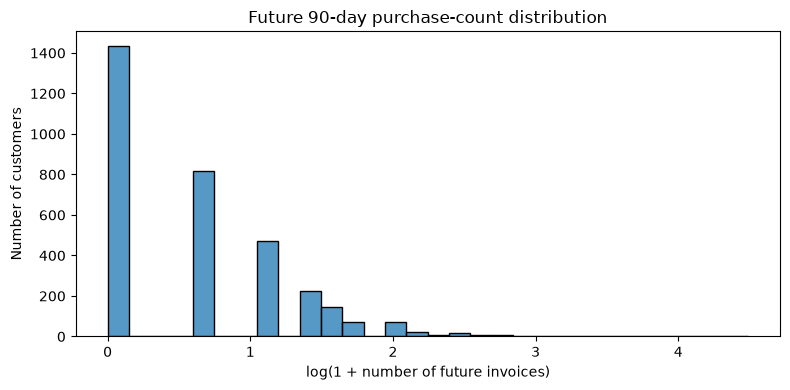

,purchase_count_90d
count,3317.000000
mean,1.484172
std,3.105621
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,88.000000


Share with zero future invoices: 0.433
Share with at least 3 future invoices: 0.18


In [45]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(np.log1p(model_data[TARGET]), bins=30, ax=ax)
ax.set(title="Future 90-day purchase-count distribution", xlabel="log(1 + number of future invoices)", ylabel="Number of customers")
plt.tight_layout()
plt.show()

display(model_data[TARGET].describe().to_frame("purchase_count_90d"))
print("Share with zero future invoices:", round((model_data[TARGET] == 0).mean(), 3))
print("Share with at least 3 future invoices:", round((model_data[TARGET] >= 3).mean(), 3))


## 7. Split customers into train, validation, and test sets

Split **after** creating one row per customer, so a customer cannot appear in multiple sets. Use a fixed random 60/20/20 split. We do not stratify because this is a count-regression target; inspect the target summaries in each split to ensure the distributions are reasonably similar.

- Training data: fit preprocessing and models.
- Validation data: select the model using MAE.
- Test data: final evaluation only, after the modelling choices are fixed.

This random split measures performance on held-out customers drawn from the same historical cohort. It is not a temporal backtest.

In [46]:
X = model_data[FEATURE_COLUMNS].copy()
y = model_data[TARGET].copy()

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Train:      {len(X_train):,} customers ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_val):,} customers ({len(X_val)/len(X):.0%})")
print(f"Test:       {len(X_test):,} customers ({len(X_test)/len(X):.0%})")

split_summary = pd.DataFrame({
    "train": y_train.describe(),
    "validation": y_val.describe(),
    "test": y_test.describe(),
}).T
display(split_summary)


Train:      1,989 customers (60%)
Validation: 664 customers (20%)
Test:       664 customers (20%)


,count,mean,std,min,25%,50%,75%,max
train,1989.0,1.520865,3.510288,0.0,0.0,1.0,2.0,88.0
validation,664.0,1.382530,2.120374,0.0,0.0,1.0,2.0,26.0
test,664.0,1.475904,2.603981,0.0,0.0,1.0,2.0,31.0


## 8. Define baselines and candidate models

We compare four approaches:

1. **Mean baseline:** predicts the mean purchase count in the training data for every customer. This is a simple non-personalized reference.
2. **Last-window count (persistence):** predicts that the customer will place the same number of invoices in the next 90 days as in the previous 90 days. This is a practical behavioural baseline.
3. **Poisson regression:** a generalized linear model with a log link, designed for non-negative count outcomes. Its conditional mean is modelled as an exponential function of the features. A key assumption is that the Poisson variance is tied to its mean (equidispersion), which may not hold in customer purchasing data.
4. **Random forest regression:** an ensemble of decision trees that can capture nonlinear relationships and interactions, without requiring feature scaling.

For Poisson regression, the features are median-imputed, transformed with `log1p` to reduce skew, and standardized. These learned transformations are inside a pipeline and are fitted only on training data. The random forest uses median imputation but does not need scaling.

In [47]:
def make_poisson_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),
        ("model", PoissonRegressor(alpha=0.5, max_iter=2000)),
    ])


def make_random_forest():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=400,
            max_features=1.0,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])

models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Poisson regression": make_poisson_model(),
    "Random forest": make_random_forest(),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted: {name}")


Fitted: Mean baseline
Fitted: Poisson regression
Fitted: Random forest


## 9. Compare models on validation data

The primary metric is **Mean Absolute Error (MAE)**: the average absolute difference between predicted and actual invoice counts, measured in invoices. **RMSE** is secondary and penalizes large errors more strongly. **Poisson deviance** is also reported because the target is a count; lower is better. **R-squared** is included as a familiar but secondary summary and may be negative if predictions are worse than predicting the test-set mean.

Predictions are kept continuous rather than rounded: for example, 1.7 represents an estimated expected count, not a literal fractional invoice. Any negative predictions are clipped to zero because negative purchase counts are impossible. Model choice is based on validation MAE, not test performance.

In [48]:
def predict_model(name, model, X_part):
    """Generate non-negative count predictions for a fitted model or baseline."""
    if name == "Last-window count (persistence)":
        predictions = X_part["recent_3m_orders"].to_numpy(dtype=float)
    else:
        predictions = model.predict(X_part)
    return np.clip(np.asarray(predictions, dtype=float), 0, None)


def regression_metrics(y_true, predictions):
    predictions = np.clip(np.asarray(predictions, dtype=float), 1e-6, None)
    return {
        "MAE (invoices)": mean_absolute_error(y_true, predictions),
        "RMSE (invoices)": np.sqrt(mean_squared_error(y_true, predictions)),
        "Poisson deviance": mean_poisson_deviance(y_true, predictions),
        "R-squared": r2_score(y_true, predictions),
    }

validation_rows = []
validation_predictions = {}

for name, model in models.items():
    val_pred = predict_model(name, model, X_val)
    validation_predictions[name] = val_pred
    validation_rows.append({"model": name, **regression_metrics(y_val, val_pred)})

# Add a behavioural persistence baseline: next-period count = previous-period count.
persistence_val_pred = predict_model("Last-window count (persistence)", None, X_val)
validation_predictions["Last-window count (persistence)"] = persistence_val_pred
validation_rows.append({
    "model": "Last-window count (persistence)",
    **regression_metrics(y_val, persistence_val_pred),
})

validation_results = pd.DataFrame(validation_rows).set_index("model").sort_values("MAE (invoices)")
display(validation_results)

selected_model_name = validation_results.index[0]
print("Selected by validation MAE:", selected_model_name)


,MAE (invoices),RMSE (invoices),Poisson deviance,R-squared
model,,,,
Last-window count (persistence),0.971386,1.567267,8.529539,0.452838
Poisson regression,1.010338,1.451920,1.430090,0.530414
Random forest,1.061330,1.559473,1.526683,0.458267
Mean baseline,1.419941,2.123287,2.369827,-0.004263


Selected by validation MAE: Last-window count (persistence)


## 10. Final evaluation on the held-out test customers

The test set has not been used for model fitting or selection. Evaluate all pre-specified approaches once to compare their final performance. The model selected using validation MAE is the primary model for interpretation.

In [49]:
test_rows = []
test_predictions = {}

for name, model in models.items():
    test_pred = predict_model(name, model, X_test)
    test_predictions[name] = test_pred
    test_rows.append({"model": name, **regression_metrics(y_test, test_pred)})

persistence_test_pred = predict_model("Last-window count (persistence)", None, X_test)
test_predictions["Last-window count (persistence)"] = persistence_test_pred
test_rows.append({
    "model": "Last-window count (persistence)",
    **regression_metrics(y_test, persistence_test_pred),
})

test_results = pd.DataFrame(test_rows).set_index("model").sort_values("MAE (invoices)")
display(test_results)

selected_test_pred = test_predictions[selected_model_name]
print("Selected model:", selected_model_name)
print("Selected model test metrics:")
display(pd.DataFrame([regression_metrics(y_test, selected_test_pred)], index=[selected_model_name]))


,MAE (invoices),RMSE (invoices),Poisson deviance,R-squared
model,,,,
Last-window count (persistence),1.055723,1.858309,7.901051,0.489947
Poisson regression,1.082949,1.789006,1.514802,0.527281
Random forest,1.130331,1.935302,1.661178,0.446807
Mean baseline,1.515009,2.602408,2.749948,-0.000299


Selected model: Last-window count (persistence)
Selected model test metrics:


,MAE (invoices),RMSE (invoices),Poisson deviance,R-squared
Last-window count (persistence),1.055723,1.858309,7.901051,0.489947


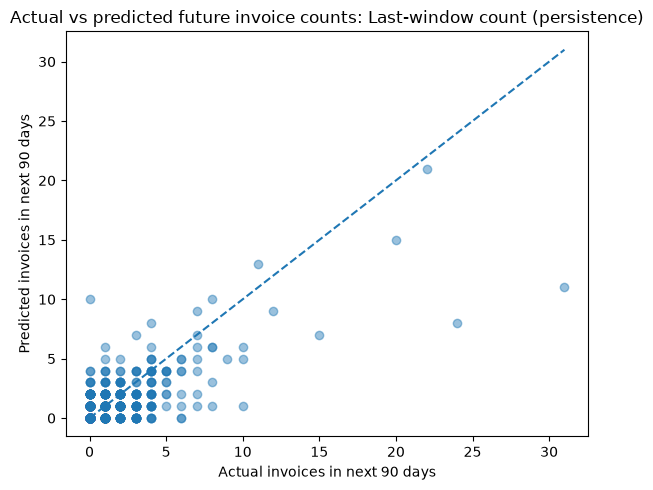

In [50]:
# Compare actual and predicted counts for the validation-selected model.
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, selected_test_pred, alpha=0.45)
max_value = max(float(y_test.max()), float(np.max(selected_test_pred)))
ax.plot([0, max_value], [0, max_value], linestyle="--")
ax.set(
    title=f"Actual vs predicted future invoice counts: {selected_model_name}",
    xlabel="Actual invoices in next 90 days",
    ylabel="Predicted invoices in next 90 days",
)
plt.tight_layout()
plt.show()


## 11. Graduate-depth component: RFM feature ablation

This analysis asks: **do additional behavioural features improve purchase-count prediction beyond standard RFM features?**

- **RFM-only features:** recency, frequency (`order_count`), and monetary value (`total_spend`).
- **Expanded feature set:** all 12 features, adding quantity purchased, product variety, active days, average order value, and average items per invoice.

Use the same random forest settings and the same train/validation/test customer split. Compare validation MAE first; report the test comparison as a pre-specified final ablation, not as a reason to keep changing the model. A difference in predictive performance is evidence about these features in this dataset and split, not proof of a causal effect.

In [51]:
RFM_COLUMNS = ["recency_days", "order_count", "total_spend"]

rfm_model = make_random_forest()
expanded_model = make_random_forest()

rfm_model.fit(X_train[RFM_COLUMNS], y_train)
expanded_model.fit(X_train[FEATURE_COLUMNS], y_train)

rfm_val_pred = np.clip(rfm_model.predict(X_val[RFM_COLUMNS]), 0, None)
expanded_val_pred = np.clip(expanded_model.predict(X_val[FEATURE_COLUMNS]), 0, None)

ablation_validation = pd.DataFrame([
    {"feature_set": "RFM only", **regression_metrics(y_val, rfm_val_pred)},
    {"feature_set": "Expanded features", **regression_metrics(y_val, expanded_val_pred)},
]).set_index("feature_set")
display(ablation_validation)

# The feature sets and comparison were specified before test evaluation.
rfm_test_pred = np.clip(rfm_model.predict(X_test[RFM_COLUMNS]), 0, None)
expanded_test_pred = np.clip(expanded_model.predict(X_test[FEATURE_COLUMNS]), 0, None)

ablation_test = pd.DataFrame([
    {"feature_set": "RFM only", **regression_metrics(y_test, rfm_test_pred)},
    {"feature_set": "Expanded features", **regression_metrics(y_test, expanded_test_pred)},
]).set_index("feature_set")
display(ablation_test)

print("Change in test MAE (expanded - RFM):",
      round(ablation_test.loc["Expanded features", "MAE (invoices)"]
            - ablation_test.loc["RFM only", "MAE (invoices)"], 4))


,MAE (invoices),RMSE (invoices),Poisson deviance,R-squared
feature_set,,,,
RFM only,1.071174,1.612480,1.605965,0.420813
Expanded features,1.061330,1.559473,1.526683,0.458267


,MAE (invoices),RMSE (invoices),Poisson deviance,R-squared
feature_set,,,,
RFM only,1.139291,1.926152,1.696691,0.452026
Expanded features,1.130331,1.935302,1.661178,0.446807


Change in test MAE (expanded - RFM): -0.009


In [54]:
# Paired bootstrap confidence interval for the difference in test MAE.
#
# Difference = Expanded model MAE - RFM model MAE
# Negative values favour the expanded model.
# Positive values favour the RFM model.

# Convert predictions and actual values to NumPy arrays.
y_actual = np.asarray(y_test, dtype=float).ravel()
rfm_predictions = np.asarray(rfm_test_pred, dtype=float).ravel()
expanded_predictions = np.asarray(expanded_test_pred, dtype=float).ravel()

# Check that both models were evaluated on the same test customers.
assert len(y_actual) == len(rfm_predictions) == len(expanded_predictions)
assert len(y_actual) > 0

# Calculate the absolute error for each customer.
rfm_errors = np.abs(y_actual - rfm_predictions)
expanded_errors = np.abs(y_actual - expanded_predictions)

# Observed difference in MAE.
observed_difference = expanded_errors.mean() - rfm_errors.mean()

# Bootstrap settings.
N_BOOTSTRAPS = 10_000
rng = np.random.default_rng(RANDOM_STATE)

n_test = len(y_actual)
bootstrap_differences = np.empty(N_BOOTSTRAPS)

# Resample test customers with replacement.
# The SAME sampled customers are used for both models.
for i in range(N_BOOTSTRAPS):

    sampled_indices = rng.integers(
        low=0,
        high=n_test,
        size=n_test
    )

    rfm_bootstrap_mae = rfm_errors[sampled_indices].mean()
    expanded_bootstrap_mae = expanded_errors[sampled_indices].mean()

    bootstrap_differences[i] = (
        expanded_bootstrap_mae - rfm_bootstrap_mae
    )

# Calculate the 95% percentile confidence interval.
ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

print(f"Test customers: {n_test}")
print(f"RFM test MAE: {rfm_errors.mean():.4f}")
print(f"Expanded test MAE: {expanded_errors.mean():.4f}")
print(f"Observed MAE difference (Expanded - RFM): {observed_difference:.4f}")
print(f"95% bootstrap confidence interval: [{ci_lower:.4f}, {ci_upper:.4f}]")

Test customers: 664
RFM test MAE: 1.1393
Expanded test MAE: 1.1303
Observed MAE difference (Expanded - RFM): -0.0090
95% bootstrap confidence interval: [-0.0361, 0.0179]


## 12. Error analysis: where does the model struggle?

Count prediction errors may be very different for customers who make no future purchases and customers who purchase frequently. Inspect the error distribution and summarize performance by the **actual** future purchase-count group. This analysis can reveal whether the model tends to underpredict frequent purchasers or overpredict customers who do not return.

In [52]:
error_table = X_test.copy()
error_table["actual_purchase_count"] = y_test
error_table["predicted_purchase_count"] = selected_test_pred
error_table["signed_error_actual_minus_predicted"] = (
    error_table["actual_purchase_count"] - error_table["predicted_purchase_count"]
)
error_table["absolute_error"] = error_table["signed_error_actual_minus_predicted"].abs()

# Positive signed error means the model underpredicted; negative means it overpredicted.
print("Largest absolute errors:")
display(error_table.sort_values("absolute_error", ascending=False).head(12))

error_table["actual_count_group"] = pd.cut(
    error_table["actual_purchase_count"],
    bins=[-0.1, 0, 1, 3, np.inf],
    labels=["0", "1", "2–3", "4+"],
)
error_by_group = error_table.groupby("actual_count_group", observed=False).agg(
    customers=("actual_purchase_count", "size"),
    mean_actual=("actual_purchase_count", "mean"),
    mean_prediction=("predicted_purchase_count", "mean"),
    MAE=("absolute_error", "mean"),
    mean_signed_error=("signed_error_actual_minus_predicted", "mean"),
)
display(error_by_group)


Largest absolute errors:


,recency_days,order_count,avg_monthly_orders,items_purchased,avg_monthly_quantity,total_spend,avg_monthly_spend,unique_products,active_days,avg_order_value,avg_items_per_order,recent_3m_orders,actual_purchase_count,predicted_purchase_count,signed_error_actual_minus_predicted,absolute_error
CustomerID,,,,,,,,,,,,,,,,
18102,26.347917,26,2.888889,29793,3310.333333,130537.23,14504.136667,54,15,5020.662692,1145.884615,11,31,11.0,20.0,20.0
17450,8.550000,22,2.444444,31872,3541.333333,85610.34,9512.260000,107,16,3891.379091,1448.727273,8,24,8.0,16.0,16.0
18073,14.415278,12,1.333333,3102,344.666667,3859.82,428.868889,23,10,321.651667,258.500000,10,0,10.0,-10.0,10.0
16705,44.489583,9,1.000000,3489,387.666667,8194.43,910.492222,81,5,910.492222,387.666667,1,10,1.0,9.0,9.0
12569,7.420139,12,1.333333,788,87.555556,1883.02,209.224444,45,10,156.918333,65.666667,7,15,7.0,8.0,8.0
15482,65.563194,4,0.444444,675,75.000000,1928.30,214.255556,17,3,482.075000,168.750000,1,8,1.0,7.0,7.0
15502,23.510417,5,0.555556,3761,417.888889,5955.53,661.725556,148,4,1191.106000,752.200000,1,7,1.0,6.0,6.0
16426,176.343750,1,0.111111,157,17.444444,328.37,36.485556,11,1,328.370000,157.000000,0,6,0.0,6.0,6.0
15351,269.507639,1,0.111111,129,14.333333,274.67,30.518889,49,1,274.670000,129.000000,0,6,0.0,6.0,6.0


,customers,mean_actual,mean_prediction,MAE,mean_signed_error
actual_count_group,,,,,
0,283,0.000000,0.628975,0.628975,-0.628975
1,168,1.000000,0.875000,0.696429,0.125000
2–3,141,2.326241,1.326241,1.312057,1.000000
4+,72,6.722222,4.069444,3.069444,2.652778


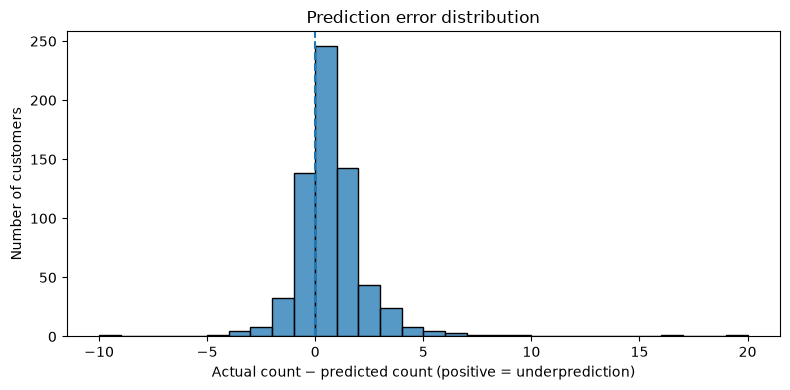

In [53]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(error_table["signed_error_actual_minus_predicted"], bins=30, ax=ax)
ax.axvline(0, linestyle="--")
ax.set(
    title="Prediction error distribution",
    xlabel="Actual count − predicted count (positive = underprediction)",
    ylabel="Number of customers",
)
plt.tight_layout()
plt.show()


## 13. Interpretation checklist for the paper and defense

Use your actual outputs to answer these questions. Do not invent or assume results before running the notebook.

1. **Problem and population:** How many active customers were eligible? What exactly counts as a purchase? Why are customers without an observation-window purchase excluded?
2. **Target distribution:** What proportion of customers had zero future invoices? What are the mean, median, and upper percentiles of the target? Is the distribution strongly right-skewed?
3. **Baselines:** Does either ML model improve on the mean baseline and the previous-window-count baseline? Explain the practical meaning of the MAE in invoices.
4. **Method assumptions:** Does Poisson regression's equidispersion assumption look plausible? How does the more flexible random forest compare?
5. **Graduate-depth analysis:** Does the expanded feature set improve on RFM-only features? How large is the MAE difference? Is it meaningful relative to the average count and the overall baseline error?
6. **Errors:** Does the model underpredict customers with many future purchases? How well does it predict zero-purchase customers?
7. **Limitations:** One retailer, one historical cutoff, one 90-day horizon, a selected active-customer population, and a random customer split. Purchase invoices are an operational proxy for orders. Excluding return lines means the target is not net purchases after returns.

### Reproducibility record

Record the dataset citation/DOI, Python and package versions, random seed (`42`), date boundaries, cleaning rules, feature definitions, split proportions, model settings, and metrics. Save the executed notebook and any tables/plots requested by the course. Do not include credentials or private data.